# Text-to-SQL fine-tuning — **v2**: cleaned data + 2 epochs

Same model (`Qwen/Qwen2.5-1.5B-Instruct`), same LoRA setup, same 300 test questions as v1. Two changes:

1. **Data cleaning.** In v1, ~23% of training targets used MySQL/PostgreSQL-only syntax (`YEAR()`, `EXTRACT(... FROM ...)`, `DATE_SUB`, `NOW()`...).
   The model learned it and produced SQL that SQLite can't run. v2 trains only on rows whose gold SQL runs in SQLite (`prepare_data.py --sqlite-only`).
2. **2 epochs instead of 1.** The adapter is saved at the end of **each** epoch and both are evaluated, so the two effects can be separated:

| compare | isolates the effect of |
|---|---|
| v1 → v2 epoch 1 | data cleaning (same 1 epoch) |
| v2 epoch 1 → v2 epoch 2 | a second epoch (same data) |

**Drive-safe:** everything runs on the Colab VM's local disk (`/content/text-to-sql-finetuning`); Google Drive is only used for
backups (checkpoints, adapters, results), and every Drive access is wrapped so a Drive disconnect
("Transport endpoint is not connected") can't crash training. **Don't move/delete files in the Drive folder while it runs.**

**Before running on Colab:** GPU runtime (L4/A100). In `MyDrive/text-to-sql-finetuning/`, replace `prepare_data.py` with the **new** version (it has the `--sqlite-only` flag; the data cell checks and asks you to upload it if it's old).
`v1/results/` is reused for the base-model and v1 numbers if present (saves ~5 min); otherwise the base model is evaluated again.

**Folder layout** (shared data outside, each version in its own folder):
```
text-to-sql-finetuning/
├── prepare_data.py        shared
├── data/test.jsonl        shared test set
├── data/v1/  data/v2/     per-version train/val
├── v1/  (notebook, results/, outputs/)
└── v2/  (this notebook, results/, outputs/)
```

In [1]:
import os, sys, subprocess
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "transformers>=4.45", "peft>=0.13", "accelerate", "datasets", "rouge_score"], check=True)
    # Colab's preinstalled torchao is older than new peft accepts ("incompatible version of torchao");
    # we don't use quantization, so remove it.
    subprocess.run([sys.executable, "-m", "pip", "uninstall", "-y", "-q", "torchao"], check=True)
    from google.colab import drive
    drive.mount("/content/drive")

Mounted at /content/drive


## 1. Config

In [2]:
MODEL_ID    = "Qwen/Qwen2.5-1.5B-Instruct"
# Work on local disk; Drive (if any) is only a backup target. Env overrides are for local testing.
DRIVE_DIR   = os.environ.get("DRIVE_DIR") or ("/content/drive/MyDrive/text-to-sql-finetuning" if IN_COLAB else None)
PROJECT_DIR = os.environ.get("WORK_DIR") or ("/content/text-to-sql-finetuning" if IN_COLAB else os.getcwd())

SMOKE_TEST = os.environ.get("SMOKE_TEST", "0") == "1"

N_TRAIN        = None    # None = all of data/v2/train.jsonl (10k)
N_EVAL         = 300
MAX_LEN        = 1024
MAX_NEW_TOKENS = 320
GEN_BATCH      = 16

LORA_R, LORA_ALPHA, LORA_DROPOUT = 16, 32, 0.05
EPOCHS, LR = 2, 2e-4              # v2: 2 epochs (~1250 steps); adapter saved after each epoch
BATCH, GRAD_ACCUM = 8, 2
MAX_STEPS = -1

if SMOKE_TEST:
    MODEL_ID = os.environ.get("SMOKE_MODEL", "Qwen/Qwen2.5-0.5B-Instruct")
    N_TRAIN, N_EVAL, MAX_NEW_TOKENS, GEN_BATCH = 8, 6, 96, 6
    BATCH, GRAD_ACCUM = 2, 1      # 4 steps per epoch

RUN_NAME       = MODEL_ID.split("/")[-1].lower() + "-text2sql-lora-v2" + ("-smoke" if SMOKE_TEST else "")
VERSION_DIR    = os.path.join(PROJECT_DIR, "v2")
DATA_DIR       = os.path.join(PROJECT_DIR, "data", "v2")             # v2 train/val (SQLite-only)
TEST_PATH      = os.path.join(PROJECT_DIR, "data", "test.jsonl")     # shared test set
OUT_DIR        = os.path.join(VERSION_DIR, "outputs", RUN_NAME)
RESULTS_DIR    = os.path.join(VERSION_DIR, "results" + ("_smoke" if SMOKE_TEST else ""))
os.makedirs(OUT_DIR, exist_ok=True); os.makedirs(RESULTS_DIR, exist_ok=True)
os.chdir(PROJECT_DIR); sys.path.insert(0, PROJECT_DIR)

import shutil

def drive_path(local):
    return os.path.join(DRIVE_DIR, os.path.relpath(local, PROJECT_DIR))

def remount():
    if IN_COLAB:
        try:
            from google.colab import drive
            drive.mount("/content/drive", force_remount=True)
        except Exception as e:
            print("  remount failed:", e)

def to_drive(local, retries=2):
    # back up a local file/folder to the same relative path on Drive; never raises
    if not DRIVE_DIR or not os.path.exists(local):
        return False
    for attempt in range(retries + 1):
        try:
            dst = drive_path(local)
            if os.path.isdir(local):
                shutil.copytree(local, dst, dirs_exist_ok=True)
            else:
                os.makedirs(os.path.dirname(dst), exist_ok=True); shutil.copy2(local, dst)
            return True
        except OSError as e:
            print(f"[Drive backup failed ({e}); attempt {attempt + 1}/{retries + 1}]")
            remount()
    print(f"[Drive backup skipped; the files are still on local disk: {local}]")
    return False

def from_drive(local):
    # copy a file/folder that exists on Drive to the local work dir; never raises
    if not DRIVE_DIR:
        return False
    src = drive_path(local)
    try:
        if os.path.isdir(src):
            shutil.copytree(src, local, dirs_exist_ok=True); return True
        if os.path.isfile(src):
            os.makedirs(os.path.dirname(local), exist_ok=True); shutil.copy2(src, local); return True
    except OSError as e:
        print(f"[could not read {src} from Drive: {e}]")
    return False

# pull inputs from Drive: data script, any existing data, v1 results (for the comparison), earlier v2 checkpoints
for rel in ["prepare_data.py", "data", os.path.join("v1", "results"), "results", os.path.relpath(OUT_DIR, PROJECT_DIR)]:
    if from_drive(os.path.join(PROJECT_DIR, rel)):
        print("pulled from Drive:", rel)

V1_RESULTS_DIR = next((d for d in [os.path.join(PROJECT_DIR, "v1", "results"), os.path.join(PROJECT_DIR, "results")]
                       if os.path.exists(os.path.join(d, "base_predictions.jsonl"))), os.path.join(PROJECT_DIR, "v1", "results"))
print(MODEL_ID, "| work dir:", PROJECT_DIR, "| Drive backup:", DRIVE_DIR, "| epochs:", EPOCHS, "| smoke test:", SMOKE_TEST)
print("v1 results:", V1_RESULTS_DIR if os.path.exists(os.path.join(V1_RESULTS_DIR, "metrics.csv")) else "not found (base model will be re-evaluated, v1 left out of the comparison)")

pulled from Drive: prepare_data.py
pulled from Drive: data
pulled from Drive: results
pulled from Drive: v2/outputs/qwen2.5-1.5b-instruct-text2sql-lora-v2
Qwen/Qwen2.5-1.5B-Instruct | work dir: /content/text-to-sql-finetuning | Drive backup: /content/drive/MyDrive/text-to-sql-finetuning | epochs: 2 | smoke test: False
v1 results: /content/text-to-sql-finetuning/results


## 2. Cleaned data (`--sqlite-only`)
The test set is identical to v1 (same seed and filter), so all versions are scored on the same 300 questions.

In [3]:
script = os.path.join(PROJECT_DIR, "prepare_data.py")
if not os.path.exists(script) or "--name" not in open(script).read():
    print(f"prepare_data.py in {PROJECT_DIR} is missing or outdated (needs --sqlite-only / --name).")
    if not IN_COLAB:
        raise FileNotFoundError("need the new prepare_data.py")
    from google.colab import files
    print("Please upload the NEW prepare_data.py:")
    for name, content in files.upload().items():
        open(script, "wb").write(content)
    assert "--name" in open(script).read(), "uploaded prepare_data.py is still an old version"
    to_drive(script)

if not (os.path.exists(os.path.join(DATA_DIR, "train.jsonl")) and os.path.exists(TEST_PATH)):
    r = subprocess.run([sys.executable, "prepare_data.py", "--sqlite-only", "--out", os.path.join(PROJECT_DIR, "data"), "--name", "v2"],
                       capture_output=True, text=True)
    print(r.stdout[-2000:]); print(r.stderr[-3000:])
    r.check_returncode()
    to_drive(DATA_DIR); to_drive(TEST_PATH)

import json
import pandas as pd
from prepare_data import SYSTEM_PROMPT, build_user, run_sql

def read_jsonl(path, n=None):
    rows = [json.loads(l) for l in open(path)]
    return rows[:n] if n else rows

train_rows = read_jsonl(os.path.join(DATA_DIR, "train.jsonl"), N_TRAIN)
val_rows   = read_jsonl(os.path.join(DATA_DIR, "val.jsonl"), 16 if SMOKE_TEST else None)
test_rows  = read_jsonl(TEST_PATH, N_EVAL)
runnable = sum(run_sql(r["sql_context"], r["sql"]) is not None for r in train_rows)
print(f"train={len(train_rows)}  val={len(val_rows)}  test={len(test_rows)}  |  train gold SQL runnable in SQLite: {runnable}/{len(train_rows)}")

train=10000  val=500  test=300  |  train gold SQL runnable in SQLite: 10000/10000


## 3. Load the base model

In [4]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

if torch.cuda.is_available():
    DEVICE = "cuda"
    DTYPE = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16   # T4 -> fp16
elif torch.backends.mps.is_available():
    DEVICE, DTYPE = "mps", torch.float32
else:
    DEVICE, DTYPE = "cpu", torch.float32
print(DEVICE, DTYPE, torch.cuda.get_device_name(0) if DEVICE == "cuda" else "")

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
tokenizer.padding_side = "left"          # left-pad for batched generation
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

model = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=DTYPE).to(DEVICE)
print(f"{sum(p.numel() for p in model.parameters())/1e9:.2f}B parameters")

cuda torch.bfloat16 NVIDIA L4


config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

1.54B parameters


## 4. Generation + evaluation helpers

In [5]:
import re, time
from collections import Counter
from tqdm.auto import tqdm
from rouge_score import rouge_scorer

def build_prompt(context, question):
    msgs = [{"role": "system", "content": SYSTEM_PROMPT},
            {"role": "user", "content": build_user(context, question)}]
    return tokenizer.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)

@torch.no_grad()
def generate(model, prompts, batch_size=GEN_BATCH, max_new_tokens=MAX_NEW_TOKENS):
    model.eval()
    outs = []
    for i in tqdm(range(0, len(prompts), batch_size), desc="generating"):
        enc = tokenizer(prompts[i:i + batch_size], return_tensors="pt", padding=True).to(model.device)
        gen = model.generate(**enc, max_new_tokens=max_new_tokens, do_sample=False,
                             temperature=None, top_p=None, top_k=None,
                             pad_token_id=tokenizer.pad_token_id)
        outs += tokenizer.batch_decode(gen[:, enc["input_ids"].shape[1]:], skip_special_tokens=True)
    return outs

def extract_sql(text):
    m = re.search(r"```(?:sql|sqlite)?\s*(.*?)```", text, re.S | re.I)
    if m:
        return m.group(1).strip()
    m = re.search(r"\b((?:SELECT|WITH)\b.*?)(?:;|\n\n|$)", text, re.S | re.I)   # fallback: bare query
    return m.group(1).strip() if m else text.strip()

def extract_explanation(text):
    m = re.search(r"Explanation:\s*(.*)", text, re.S | re.I)
    if m:
        return m.group(1).strip()
    return re.sub(r"```.*?```", "", text, flags=re.S).strip()   # whatever prose is outside the code block

def norm_sql(s):
    return re.sub(r"\s+", " ", s.strip().rstrip(";")).lower()

def same_result(a, b):
    # multiset comparison: row order ignored, floats rounded
    norm = lambda rows: Counter(tuple(round(v, 4) if isinstance(v, float) else v for v in r) for r in rows)
    return a is not None and b is not None and norm(a) == norm(b)

_rouge = rouge_scorer.RougeScorer(["rougeL"], use_stemmer=True)

def evaluate(model, rows, tag):
    t0 = time.time()
    outputs = generate(model, [build_prompt(r["sql_context"], r["sql_prompt"]) for r in rows])
    secs = time.time() - t0
    recs = []
    for r, out in zip(rows, outputs):
        pred_sql = extract_sql(out)
        gold_res, pred_res = run_sql(r["sql_context"], r["sql"]), run_sql(r["sql_context"], pred_sql)
        recs.append({
            "id": r["id"], "sql_complexity": r["sql_complexity"], "question": r["sql_prompt"],
            "gold_sql": r["sql"], "pred_sql": pred_sql, "raw_output": out,
            "format_ok": bool(re.search(r"```sql", out, re.I)) and "explanation:" in out.lower(),
            "executable": pred_res is not None,
            "exec_match": same_result(gold_res, pred_res),
            "exact_match": norm_sql(pred_sql) == norm_sql(r["sql"]),
            "expl_rougeL": _rouge.score(r["sql_explanation"], extract_explanation(out))["rougeL"].fmeasure,
        })
    df = pd.DataFrame(recs)
    df.to_json(os.path.join(RESULTS_DIR, f"{tag}_predictions.jsonl"), orient="records", lines=True, force_ascii=False)
    summary = {"model": tag, "n": len(df), "exec_accuracy": df.exec_match.mean(), "executable_rate": df.executable.mean(),
               "exact_match": df.exact_match.mean(), "format_compliance": df.format_ok.mean(),
               "explanation_rougeL": df.expl_rougeL.mean(), "sec_per_example": secs / len(df)}
    print(pd.Series(summary).to_string())
    return df, summary

# sanity check: parsing gold-formatted text gives back the gold SQL / explanation
_t = test_rows[0]
assert extract_sql(f"```sql\n{_t['sql']}\n```\n\nExplanation: x") == _t["sql"]
assert same_result(run_sql(_t["sql_context"], _t["sql"]), run_sql(_t["sql_context"], _t["sql"]))

## 5. Baseline (before fine-tuning)
Greedy decoding on the same questions is deterministic, so v1's base-model predictions are reused when available.

In [6]:
def summarize(df, tag, sec_per_example=float("nan")):
    return {"model": tag, "n": len(df), "exec_accuracy": df.exec_match.mean(), "executable_rate": df.executable.mean(),
            "exact_match": df.exact_match.mean(), "format_compliance": df.format_ok.mean(),
            "explanation_rougeL": df.expl_rougeL.mean(), "sec_per_example": sec_per_example}

v1_base = os.path.join(V1_RESULTS_DIR, "base_predictions.jsonl")
test_ids = [r["id"] for r in test_rows]
if os.path.exists(v1_base) and pd.read_json(v1_base, lines=True).id.tolist() == test_ids:
    base_df = pd.read_json(v1_base, lines=True)
    v1_metrics = pd.read_csv(os.path.join(V1_RESULTS_DIR, "metrics.csv"), index_col="model")
    base_summary = summarize(base_df, "base", v1_metrics.loc["base", "sec_per_example"])
    print("reused v1 base-model predictions"); print(pd.Series(base_summary).to_string())
else:
    base_df, base_summary = evaluate(model, test_rows, "base")

reused v1 base-model predictions
model                     base
n                          300
exec_accuracy         0.643333
executable_rate       0.943333
exact_match           0.143333
format_compliance     0.343333
explanation_rougeL     0.36886
sec_per_example       0.636193


## 6. Tokenize for supervised fine-tuning
Loss is computed **only on the assistant answer** (SQL + explanation); system/user tokens are masked with `-100`.

In [7]:
from datasets import Dataset

def tokenize_example(ex):
    msgs = ex["messages"]
    prompt = tokenizer.apply_chat_template(msgs[:-1], tokenize=False, add_generation_prompt=True)
    full   = tokenizer.apply_chat_template(msgs, tokenize=False)          # ends with <|im_end|>
    p_ids = tokenizer(prompt, add_special_tokens=False)["input_ids"]
    f_ids = tokenizer(full, add_special_tokens=False)["input_ids"][:MAX_LEN]
    labels = [-100] * len(p_ids) + f_ids[len(p_ids):]
    return {"input_ids": f_ids, "attention_mask": [1] * len(f_ids), "labels": labels[:len(f_ids)]}

train_ds = Dataset.from_list([{"messages": r["messages"]} for r in train_rows]).map(tokenize_example, remove_columns=["messages"])
val_ds   = Dataset.from_list([{"messages": r["messages"]} for r in val_rows]).map(tokenize_example, remove_columns=["messages"])

lens = [len(x) for x in train_ds["input_ids"]]
print(f"tokens/example: mean={sum(lens)/len(lens):.0f}  max={max(lens)}  truncated={sum(l >= MAX_LEN for l in lens)}")

def collate(batch):
    # right-pad for training (generation uses left padding via the tokenizer)
    L = max(len(b["input_ids"]) for b in batch)
    pad = lambda seq, v: seq + [v] * (L - len(seq))
    return {"input_ids":      torch.tensor([pad(b["input_ids"], tokenizer.pad_token_id) for b in batch]),
            "attention_mask": torch.tensor([pad(b["attention_mask"], 0) for b in batch]),
            "labels":         torch.tensor([pad(b["labels"], -100) for b in batch])}

Map:   0%|          | 0/10000 [00:00<?, ? examples/s]

Map:   0%|          | 0/500 [00:00<?, ? examples/s]

tokens/example: mean=242  max=641  truncated=0


## 7. Add LoRA adapters
The 1.5B base weights stay frozen; only small low-rank matrices on every attention/MLP projection are trained.

In [8]:
from peft import LoraConfig, get_peft_model

model.config.use_cache = False
model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
model.enable_input_require_grads()

lora_cfg = LoraConfig(r=LORA_R, lora_alpha=LORA_ALPHA, lora_dropout=LORA_DROPOUT, task_type="CAUSAL_LM",
                      target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"])
model = get_peft_model(model, lora_cfg)
for p in model.parameters():          # keep trainable LoRA weights in fp32 (needed for fp16 AMP on T4)
    if p.requires_grad:
        p.data = p.data.float()
model.print_trainable_parameters()

trainable params: 18,464,768 || all params: 1,562,179,072 || trainable%: 1.1820


## 8. Train (2 epochs, adapter saved after each epoch)
Checkpoints are written to local disk every 100 steps and backed up to Drive. If the runtime dies, re-run the notebook: it pulls the latest checkpoint back from Drive and resumes.

In [9]:
from transformers import Trainer, TrainingArguments, TrainerCallback
from transformers.trainer_utils import get_last_checkpoint

class SaveEachEpoch(TrainerCallback):
    # keep a copy of the adapter at the end of every epoch so epoch 1 vs epoch 2 can both be evaluated
    def on_epoch_end(self, args, state, control, model=None, **kw):
        path = os.path.join(OUT_DIR, f"epoch{round(state.epoch)}_adapter")
        model.save_pretrained(path)
        to_drive(path)
        print(f"\n[epoch {round(state.epoch)}] adapter saved to {path}")

class BackupCheckpoints(TrainerCallback):
    # copy each new checkpoint to Drive and keep only the newest 2 there (each is ~220 MB)
    def on_save(self, args, state, control, **kw):
        ckpt = os.path.join(OUT_DIR, f"checkpoint-{state.global_step}")
        if not to_drive(ckpt):
            return
        try:
            d = drive_path(OUT_DIR)
            old = sorted((c for c in os.listdir(d) if c.startswith("checkpoint-")), key=lambda c: int(c.split("-")[1]))[:-2]
            for c in old:
                shutil.rmtree(os.path.join(d, c), ignore_errors=True)
        except OSError as e:
            print("[could not prune old Drive checkpoints]", e)

# warmup as an explicit step count: works on transformers v4 and v5 (v5 removed `warmup_ratio`)
total_steps = MAX_STEPS if MAX_STEPS > 0 else EPOCHS * -(-len(train_ds) // (BATCH * GRAD_ACCUM))
args = TrainingArguments(
    output_dir=OUT_DIR,
    num_train_epochs=EPOCHS, max_steps=MAX_STEPS,
    per_device_train_batch_size=BATCH, per_device_eval_batch_size=BATCH, gradient_accumulation_steps=GRAD_ACCUM,
    learning_rate=LR, lr_scheduler_type="cosine", warmup_steps=max(1, int(0.03 * total_steps)), weight_decay=0.0,
    logging_steps=2 if SMOKE_TEST else 10,
    eval_strategy="steps", eval_steps=2 if SMOKE_TEST else 100,
    save_strategy="steps", save_steps=2 if SMOKE_TEST else 100, save_total_limit=2,
    bf16=(DTYPE == torch.bfloat16), fp16=(DTYPE == torch.float16),
    report_to="none", remove_unused_columns=False,
    dataloader_pin_memory=(DEVICE == "cuda"),
)
trainer = Trainer(model=model, args=args, train_dataset=train_ds, eval_dataset=val_ds, data_collator=collate,
                  callbacks=[SaveEachEpoch(), BackupCheckpoints()])

last_ckpt = get_last_checkpoint(OUT_DIR) if os.path.isdir(OUT_DIR) else None
print("resuming from", last_ckpt) if last_ckpt else print("starting fresh")
t0 = time.time()
trainer.train(resume_from_checkpoint=last_ckpt)
train_minutes = (time.time() - t0) / 60
print(f"training took {train_minutes:.1f} min  ({total_steps} steps)")

ADAPTER_DIR = os.path.join(OUT_DIR, "final_adapter")        # = end of epoch 2
model.save_pretrained(ADAPTER_DIR); tokenizer.save_pretrained(ADAPTER_DIR)
json.dump(trainer.state.log_history, open(os.path.join(RESULTS_DIR, "train_log.json"), "w"), indent=1)
to_drive(ADAPTER_DIR); to_drive(RESULTS_DIR)
print("adapter saved to", ADAPTER_DIR)

starting fresh


Step,Training Loss,Validation Loss
100,0.373695,0.384190
200,0.355515,0.370237
300,0.365612,0.364737
400,0.341277,0.358278
500,0.349631,0.353074
600,0.354003,0.348778
700,0.319286,0.346649
800,0.293064,0.349010
900,0.309661,0.345853
1000,0.298100,0.345202



[epoch 1] adapter saved to /content/text-to-sql-finetuning/v2/outputs/qwen2.5-1.5b-instruct-text2sql-lora-v2/epoch1_adapter

[epoch 2] adapter saved to /content/text-to-sql-finetuning/v2/outputs/qwen2.5-1.5b-instruct-text2sql-lora-v2/epoch2_adapter
training took 60.9 min  (1250 steps)
adapter saved to /content/text-to-sql-finetuning/v2/outputs/qwen2.5-1.5b-instruct-text2sql-lora-v2/final_adapter


## 9. Evaluate after epoch 2, then after epoch 1

In [10]:
model.config.use_cache = True
e2_df, e2_summary = evaluate(model, test_rows, "v2_epoch2")
to_drive(RESULTS_DIR)

generating:   0%|          | 0/19 [00:00<?, ?it/s]

model                 v2_epoch2
n                           300
exec_accuracy          0.736667
executable_rate        0.973333
exact_match                0.36
format_compliance           1.0
explanation_rougeL     0.547724
sec_per_example        0.778837


True

In [11]:
# swap the epoch-1 LoRA weights into the same model and evaluate again
from peft import set_peft_model_state_dict
from safetensors.torch import load_file

EPOCH1_DIR = os.path.join(OUT_DIR, "epoch1_adapter")
set_peft_model_state_dict(model, load_file(os.path.join(EPOCH1_DIR, "adapter_model.safetensors")))
e1_df, e1_summary = evaluate(model, test_rows, "v2_epoch1")
to_drive(RESULTS_DIR)

generating:   0%|          | 0/19 [00:00<?, ?it/s]

model                 v2_epoch1
n                           300
exec_accuracy          0.733333
executable_rate        0.966667
exact_match            0.333333
format_compliance           1.0
explanation_rougeL     0.556659
sec_per_example        0.745079


True

## 10. Compare: base vs v1 vs v2 (epoch 1, epoch 2)

In [12]:
summaries, dfs = [base_summary], {"base": base_df}
v1_pred = os.path.join(V1_RESULTS_DIR, "finetuned_predictions.jsonl")
if os.path.exists(v1_pred) and not SMOKE_TEST:
    v1_df = pd.read_json(v1_pred, lines=True)
    summaries.append(summarize(v1_df, "v1"))
    dfs["v1"] = v1_df
summaries += [e1_summary, e2_summary]; dfs.update({"v2_epoch1": e1_df, "v2_epoch2": e2_df})

metrics = pd.DataFrame(summaries).set_index("model")
metrics.to_csv(os.path.join(RESULTS_DIR, "metrics.csv"))

by_cx = pd.DataFrame({"n": base_df.groupby("sql_complexity").size(),
                      **{k: d.groupby("sql_complexity").exec_match.mean() for k, d in dfs.items()}}).sort_values("n", ascending=False)
by_cx.to_csv(os.path.join(RESULTS_DIR, "exec_accuracy_by_complexity.csv"))

display(metrics.style.format("{:.3f}"))
display(by_cx.style.format({k: "{:.1%}" for k in dfs}))

,n,exec_accuracy,executable_rate,exact_match,format_compliance,explanation_rougeL,sec_per_example
model,,,,,,,
base,300.000,0.643,0.943,0.143,0.343,0.369,0.636
v1,300.000,0.673,0.913,0.320,1.000,0.539,nan
v2_epoch1,300.000,0.733,0.967,0.333,1.000,0.557,0.745
v2_epoch2,300.000,0.737,0.973,0.360,1.000,0.548,0.779


,n,base,v1,v2_epoch1,v2_epoch2
sql_complexity,,,,,
basic SQL,162,73.5%,77.8%,82.7%,84.6%
aggregation,66,48.5%,53.0%,62.1%,59.1%
single join,40,65.0%,65.0%,72.5%,75.0%
subqueries,14,71.4%,64.3%,71.4%,71.4%
window functions,10,20.0%,0.0%,0.0%,0.0%
multiple_joins,5,60.0%,80.0%,80.0%,80.0%
set operations,3,33.3%,66.7%,66.7%,33.3%


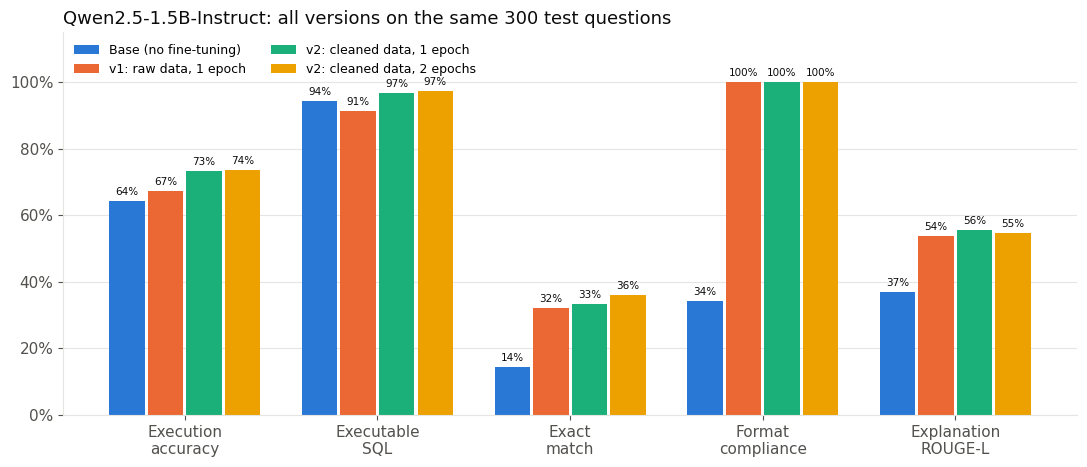

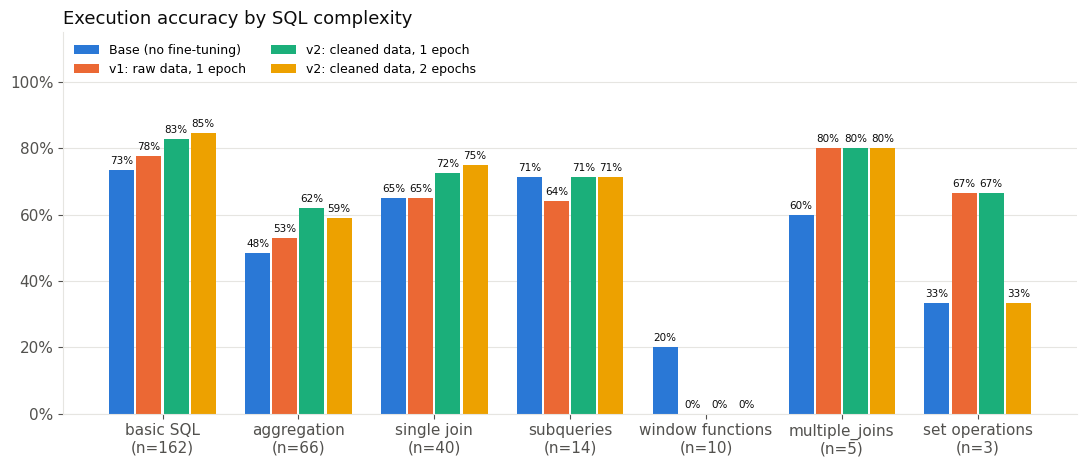

In [13]:
import matplotlib.pyplot as plt

# fixed categorical order (base, v1, v2-e1, v2-e2) so each version keeps its color across charts
COLORS = {"base": "#2a78d6", "v1": "#eb6834", "v2_epoch1": "#1baf7a", "v2_epoch2": "#eda100"}
LABELS = {"base": "Base (no fine-tuning)", "v1": "v1: raw data, 1 epoch",
          "v2_epoch1": "v2: cleaned data, 1 epoch", "v2_epoch2": "v2: cleaned data, 2 epochs"}
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e6e5e1"
plt.rcParams.update({"font.size": 11, "axes.edgecolor": GRID, "axes.labelcolor": MUTED,
                     "xtick.color": MUTED, "ytick.color": MUTED, "axes.spines.top": False, "axes.spines.right": False})

def grouped_bars(ax, labels, series, title):
    k = len(series); w = 0.8 / k
    for j, (name, vals) in enumerate(series.items()):
        xs = [i - 0.4 + w * (j + 0.5) for i in range(len(labels))]
        bars = ax.bar(xs, vals, w * 0.92, color=COLORS[name], label=LABELS[name], zorder=2)
        for b, v in zip(bars, vals):
            ax.text(b.get_x() + b.get_width()/2, v + 0.012, f"{v:.0%}", ha="center", va="bottom", fontsize=7.5, color=INK)
    ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels)
    ax.set_ylim(0, 1.15); ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
    ax.grid(axis="y", color=GRID, zorder=0); ax.set_title(title, loc="left", color=INK, fontsize=13)
    ax.legend(frameon=False, loc="upper left", ncol=2, fontsize=9)

cols = ["exec_accuracy", "executable_rate", "exact_match", "format_compliance", "explanation_rougeL"]
names = ["Execution\naccuracy", "Executable\nSQL", "Exact\nmatch", "Format\ncompliance", "Explanation\nROUGE-L"]
fig, ax = plt.subplots(figsize=(11, 4.8))
grouped_bars(ax, names, {m: metrics.loc[m, cols].values for m in metrics.index},
             f"{MODEL_ID.split('/')[-1]}: all versions on the same {len(test_rows)} test questions")
fig.tight_layout(); fig.savefig(os.path.join(RESULTS_DIR, "all_versions_metrics.png"), dpi=200); plt.show()

fig, ax = plt.subplots(figsize=(11, 4.8))
grouped_bars(ax, [f"{c}\n(n={n})" for c, n in by_cx.n.items()], {m: by_cx[m].values for m in dfs},
             "Execution accuracy by SQL complexity")
fig.tight_layout(); fig.savefig(os.path.join(RESULTS_DIR, "exec_accuracy_by_complexity.png"), dpi=200); plt.show()

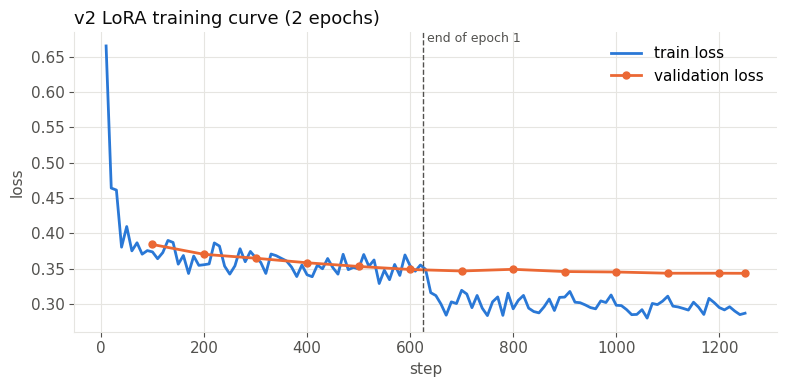

In [14]:
log = pd.DataFrame(trainer.state.log_history)
tr, ev = log.dropna(subset=["loss"]), log.dropna(subset=["eval_loss"])
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(tr.step, tr.loss, color=COLORS["base"], lw=2, label="train loss")
ax.plot(ev.step, ev.eval_loss, color=COLORS["v1"], lw=2, marker="o", ms=5, label="validation loss")
ax.axvline(total_steps / EPOCHS, color=MUTED, lw=1, ls="--"); ax.text(total_steps / EPOCHS, ax.get_ylim()[1], " end of epoch 1",
                                                               va="top", fontsize=9, color=MUTED)
ax.set_xlabel("step"); ax.set_ylabel("loss"); ax.grid(color=GRID)
ax.set_title("v2 LoRA training curve (2 epochs)", loc="left", color=INK, fontsize=13); ax.legend(frameon=False, loc="upper right")
fig.tight_layout(); fig.savefig(os.path.join(RESULTS_DIR, "loss_curve.png"), dpi=200); plt.show()

## 11. Error analysis + examples (for the slides)

In [15]:
import re
def dialect_errors(df):
    # predictions using MySQL/Postgres-only functions that SQLite rejects
    pat = r"\b(?:YEAR|MONTH|EXTRACT|DATE_SUB|DATE_ADD|DATEADD|NOW|CURDATE)\s*\(|\bSEPARATOR\b|\bINTERVAL\b"
    return int(df.pred_sql.str.contains(pat, flags=re.I, regex=True).sum())

err = pd.DataFrame({k: {"wrong answers": int((~d.exec_match).sum()), "non-executable SQL": int((~d.executable).sum()),
                        "uses MySQL/Postgres-only syntax": dialect_errors(d)} for k, d in dfs.items()}).T
err.to_csv(os.path.join(RESULTS_DIR, "error_breakdown.csv")); display(err)

best_tag = max(["v2_epoch1", "v2_epoch2"], key=lambda t: metrics.loc[t, "exec_accuracy"])
best_df = dfs[best_tag]
cmp = base_df.merge(best_df, on=["id", "question", "gold_sql", "sql_complexity"], suffixes=("_base", "_ft"))
fixed = cmp[~cmp.exec_match_base & cmp.exec_match_ft]
print(f"best v2 = {best_tag}.  fixed vs base: {len(fixed)}   broken vs base: {(cmp.exec_match_base & ~cmp.exec_match_ft).sum()}")

lines = [f"# Before vs after examples (base vs {best_tag})\n"]
for _, r in fixed.head(5).iterrows():
    lines += [f"## [{r.sql_complexity}] {r.question}\n", f"**Gold SQL:** `{r.gold_sql}`\n",
              "**Before (base):**\n", "~~~\n" + r.raw_output_base.strip() + "\n~~~\n",
              f"**After ({best_tag}):**\n", "~~~\n" + r.raw_output_ft.strip() + "\n~~~\n"]
open(os.path.join(RESULTS_DIR, "examples.md"), "w").write("\n".join(lines))

,wrong answers,non-executable SQL,uses MySQL/Postgres-only syntax
base,107,17,2
v1,98,26,11
v2_epoch1,80,10,0
v2_epoch2,79,8,0


best v2 = v2_epoch2.  fixed vs base: 40   broken vs base: 12


6103

In [16]:
summary = {"model": MODEL_ID, "data": "data_v2 (train/val filtered to SQLite-runnable gold SQL)",
           "train_examples": len(train_rows), "test_examples": len(test_rows),
           "lora": {"r": LORA_R, "alpha": LORA_ALPHA, "dropout": LORA_DROPOUT},
           "train": {"epochs": EPOCHS, "steps": total_steps, "lr": LR, "effective_batch": BATCH * GRAD_ACCUM,
                     "minutes": round(train_minutes, 1), "gpu": torch.cuda.get_device_name(0) if DEVICE == "cuda" else DEVICE},
           "best_v2": best_tag, "best_adapter": os.path.join(OUT_DIR, "final_adapter" if best_tag == "v2_epoch2" else "epoch1_adapter"),
           "results": {m: metrics.loc[m].to_dict() for m in metrics.index}}
json.dump(summary, open(os.path.join(RESULTS_DIR, "summary.json"), "w"), indent=2, default=float)
backed_up = to_drive(RESULTS_DIR)
print("All results written to", RESULTS_DIR,
      f"(backed up to {drive_path(RESULTS_DIR)})" if backed_up else "(NOT backed up to Drive - download the zip below)")
print("Best adapter (use this for the UI):", summary["best_adapter"])
if IN_COLAB:   # local disk is wiped when the runtime ends; also offer a zip download as a second copy
    zip_path = shutil.make_archive("/content/v2_results", "zip", RESULTS_DIR)
    from google.colab import files
    files.download(zip_path)

All results written to /content/text-to-sql-finetuning/v2/results (backed up to /content/drive/MyDrive/text-to-sql-finetuning/v2/results)
Best adapter (use this for the UI): /content/text-to-sql-finetuning/v2/outputs/qwen2.5-1.5b-instruct-text2sql-lora-v2/final_adapter


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>